In [1]:
from matplotlib.ticker import MaxNLocator
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns
import pandas as pd
import numpy as np
import torch
import glob
import math
import sys

rc = {
    "axes.axisbelow": True,
    "axes.linewidth": 1.0,
    "axes.labelsize": "x-small",
    "axes.titlesize": "x-small",
    "figure.dpi": 150,
    "figure.figsize": (3.2, 3.2),
    "font.size": 12.0,
    "legend.fontsize": "xx-small",
    "lines.linewidth": 1.0,
    "savefig.transparent": True,
    "xtick.labelsize": "xx-small",
    "xtick.major.width": 1.0,
    "ytick.labelsize": "xx-small",
    "ytick.major.width": 1.0,
    "font.family": ["serif"],
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsfonts}",
}

plt.rcParams.update(rc)

PROJECT_ROOT = "/Users/gabrieleaccarino/Workspace/waveletflux"
sys.path.insert(0, PROJECT_ROOT)

from waveletflux.utils.eval import build_stats_df, build_psd_df
from waveletflux.utils.plot import plot_psd, plot_psd_seaborn
from waveletflux.utils.well_data import get_well_dataset

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

In [2]:
PDEs = ['turbulent_radiative_layer_2D', 'rayleigh_benard', 'active_matter']

model_checklist = [
    'WaveletFlow_1scale_db2_v4.0',
    'WaveletFlow_3scales_db2_v4.0',
    'FM_data_space_v4.0',
    'FourierFlow_v4.0',
    'FNO',
    'TFNO',
    'UNetClassic',
    'UNetConvNext',
]

generative_models = [
    'FM_data_space_v4.0',
    'FourierFlow_v4.0',
]

ours = [
    'WaveletFlow_1scale_db2_v4.0',
    'WaveletFlow_3scales_db2_v4.0',
]

In [3]:
GT_LABEL = "Ground-truth"

def enrich(df, stem, model_name, dataset_name):
    """Add metadata columns, preserving GT rows already labelled in the CSV."""
    parts     = stem.split('_')
    nsampling = next((p.replace('nsampling', '') for p in parts if p.startswith('nsampling')), None)
    nens      = next((p.replace('nens',      '') for p in parts if p.startswith('nens')),      None)
    if 'model' in df.columns:
        df.loc[df['model'] != GT_LABEL, 'model'] = model_name
    else:
        df['model'] = model_name
    df['source']    = stem
    df['dataset']   = dataset_name
    df['pde']       = dataset_name          # ← new: explicit PDE tag
    df['nsampling'] = int(nsampling) if nsampling else None
    df['nens']      = int(nens)      if nens      else None
    return df

dfs_stats, dfs_psd = [], []

for pde in PDEs:
    print(f"\n{'='*60}\nLoading PDE: {pde}\n{'='*60}")
    for model in model_checklist:
        pattern_stats = f'{PROJECT_ROOT}/experiments/{pde}/metrics/{model}*stats.csv'
        pattern_psd   = f'{PROJECT_ROOT}/experiments/{pde}/metrics/{model}*psd.csv'
        matched_files_stats = glob.glob(pattern_stats)
        matched_files_psd   = glob.glob(pattern_psd)

        if not matched_files_stats:
            print(f"  [WARN] No stats files for model '{model}' | pde '{pde}'")
        if not matched_files_psd:
            print(f"  [WARN] No psd   files for model '{model}' | pde '{pde}'")

        for fpath in sorted(matched_files_stats):
            try:
                df   = pd.read_csv(fpath)
                stem = Path(fpath).stem
                df   = enrich(df, stem, model, pde)
                dfs_stats.append(df)
                print(f"  [OK stats] {df.shape} | {Path(fpath).name:70s}")
            except Exception as e:
                print(f"  [ERR] {fpath}: {e}")

        for fpath in sorted(matched_files_psd):
            try:
                df   = pd.read_csv(fpath)
                stem = Path(fpath).stem
                df   = enrich(df, stem, model, pde)
                dfs_psd.append(df)
                print(f"  [OK psd  ] {df.shape} | {Path(fpath).name:70s}")
            except Exception as e:
                print(f"  [ERR] {fpath}: {e}")

# ── Concat & deduplicate ───────────────────────────────────────────────────────
DEDUP_EXCLUDE = {'source', 'nsampling', 'nens'}

if dfs_stats:
    stats_df = pd.concat(dfs_stats, ignore_index=True)
    stats_df = stats_df.drop_duplicates(
        subset=[c for c in stats_df.columns if c not in DEDUP_EXCLUDE]
    )
    print(f"\nstats_df: {stats_df.shape}  |  columns: {list(stats_df.columns)}")
else:
    stats_df = pd.DataFrame()
    print("[WARN] No data loaded — stats_df is empty.")

if dfs_psd:
    psd_df = pd.concat(dfs_psd, ignore_index=True)
    psd_df = psd_df.drop_duplicates(
        subset=[c for c in psd_df.columns if c not in DEDUP_EXCLUDE]
    )
    print(f"\npsd_df:   {psd_df.shape}  |  columns: {list(psd_df.columns)}")
else:
    psd_df = pd.DataFrame()
    print("[WARN] No data loaded — psd_df is empty.")


Loading PDE: turbulent_radiative_layer_2D
  [OK stats] (3492, 35) | WaveletFlow_1scale_db2_v4.0_nsampling50_nens8_turbulent_radiative_layer_2D_stats.csv
  [OK psd  ] (2828520, 15) | WaveletFlow_1scale_db2_v4.0_nsampling50_nens8_turbulent_radiative_layer_2D_psd.csv
  [OK stats] (3492, 35) | WaveletFlow_3scales_db2_v4.0_nsampling50_nens8_turbulent_radiative_layer_2D_stats.csv
  [OK psd  ] (2828520, 15) | WaveletFlow_3scales_db2_v4.0_nsampling50_nens8_turbulent_radiative_layer_2D_psd.csv
  [OK stats] (3492, 35) | FM_data_space_v4.0_nsampling50_nens8_turbulent_radiative_layer_2D_stats.csv
  [OK psd  ] (2828520, 15) | FM_data_space_v4.0_nsampling50_nens8_turbulent_radiative_layer_2D_psd.csv
  [OK stats] (3492, 35) | FourierFlow_v4.0_32modes_nsampling50_nens8_turbulent_radiative_layer_2D_stats.csv
  [OK psd  ] (2828520, 15) | FourierFlow_v4.0_32modes_nsampling50_nens8_turbulent_radiative_layer_2D_psd.csv
  [OK stats] (3492, 35) | FNO_turbulent_radiative_layer_2D_stats.csv                   

# Config

## Palette

In [4]:
#palette = sns.cubehelix_palette(len(model_checklist), start=8, dark=0.25)
#palette = sns.cubehelix_palette(len(model_checklist), start=2, dark=0.25)
palette = sns.color_palette("husl", len(model_checklist))
model_palette = {model: palette[idx] for idx, model in enumerate(model_checklist)}
palette

[(0.9677975592919913, 0.44127456009157356, 0.5358103155058701),
 (0.8087954113106306, 0.5634700050056693, 0.19502642696727285),
 (0.5920891529639701, 0.6418467016378244, 0.1935069134991043),
 (0.19783576093349015, 0.6955516966063037, 0.3995301037444499),
 (0.21044753832183283, 0.6773105080456748, 0.6433941168468681),
 (0.22335772267769388, 0.6565792317435265, 0.8171355503265633),
 (0.6423044349219739, 0.5497680051256467, 0.9582651433656727),
 (0.96038885399407, 0.3814317878772117, 0.8683117650835491)]

## Compute horizon and model_type attributes

In [5]:
field_names = stats_df['field'].unique()
n_fields = len(field_names)

stats_df['step'] = stats_df['step'] + 1
psd_df['step']   = psd_df['step'] + 1

aggregate_mode = "mean"

"""
def horizon_rayleigh_benard(t):
    if t < 32:
        return "01:32"
    elif t < 64:
        return "33:64"
    else:
        return "65:196"
"""

def horizon_rayleigh_benard(t):
    if t < 20:
        return "01:20"
    elif t < 60:
        return "21:60"
    else:
        return "61:196"

 
def horizon_active_matter(t):
    if t < 24:
        return "01:24"
    elif t < 52:
        return "25:52"
    else:
        return "52:77"
    
#def horizon_turbulent_radiative_layer_2D(t):
#    if t < 32:
#        return "01:32"
#    elif t < 64:
#        return "33:64"
#    else:
#        return "65:97"
    
def horizon_turbulent_radiative_layer_2D(t):
    if t < 20:
        return "01:20"
    elif t < 60:
        return "21:60"
    else:
        return "61:97"

def aggregate(x):
    if "mean" in aggregate_mode:
        return np.nanmean(x)
    elif "median" in aggregate_mode:
        return np.nanmedian(x)

def model_type(model):
    if model in generative_models:
        return "generative"
    if model in ours:
        return "ours"
    return "deterministic"

# ── Horizon: write into matching rows only, don't overwrite the full column ───
horizon_fn = {
    'turbulent_radiative_layer_2D': horizon_turbulent_radiative_layer_2D,
    'rayleigh_benard':              horizon_rayleigh_benard,
    'active_matter':                horizon_active_matter,
}

for df in (stats_df, psd_df):
    df["horizon"] = np.nan                          # initialise once
    for pde, fn in horizon_fn.items():
        mask = df["pde"] == pde
        df.loc[mask, "horizon"] = df.loc[mask, "step"].apply(fn)

#stats_df["horizon"] = stats_df[stats_df['pde'] == 'turbulent_radiative_layer_2D']["step"].apply(horizon_turbulent_radiative_layer_2D)
#stats_df["horizon"] = stats_df[stats_df['pde'] == 'rayleigh_benard']["step"].apply(horizon_rayleigh_benard)
#stats_df["horizon"] = stats_df[stats_df['pde'] == 'active_matter']["step"].apply(horizon_active_matter)
#stats_df["horizon"] = stats_df["step"].apply(horizon)
stats_df["model_type"] = stats_df["model"].apply(model_type)
stats_df["spread_skill_new"] = (stats_df["spread"] + 1e-3) / (stats_df["rmse"] + 1e-3)

#psd_df["horizon"] = psd_df[psd_df['pde'] == 'turbulent_radiative_layer_2D']["step"].apply(horizon_turbulent_radiative_layer_2D)
#psd_df["horizon"] = psd_df[psd_df['pde'] == 'rayleigh_benard']["step"].apply(horizon_rayleigh_benard)
#psd_df["horizon"] = psd_df[psd_df['pde'] == 'active_matter']["step"].apply(horizon_active_matter)
#psd_df["horizon"] = psd_df["step"].apply(horizon)
psd_df["model_type"] = psd_df["model"].apply(model_type)

/var/folders/ch/y8sfh_4n0879ll031cvbsv380000gn/T/ipykernel_37567/2297497491.py:76: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['01:20' '01:20' '01:20' ... '61:97' '61:97' '61:97']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[mask, "horizon"] = df.loc[mask, "step"].apply(fn)
/var/folders/ch/y8sfh_4n0879ll031cvbsv380000gn/T/ipykernel_37567/2297497491.py:76: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['01:20' '01:20' '01:20' ... '61:97' '61:97' '61:97']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[mask, "horizon"] = df.loc[mask, "step"].apply(fn)


# Figure 1: Spectral Coherence RMSE

In [6]:
PDE_LABELS = {
    'turbulent_radiative_layer_2D' : 'Turbulent Radiative Layer 2D',
    'rayleigh_benard'              : 'Rayleigh-Bénard Convection',
    'active_matter'                : 'Active Matter',
    }

# x-axis limits for PDE
pde_xlims = {
    'turbulent_radiative_layer_2D' : (-5, 100),
    'rayleigh_benard'              : (-5, 200),
    'active_matter'                : (-5, 80),
    }

band_ylims = {
    "Low"   : (-0.01, 0.5), 
    "Mid"   : (-0.01, 0.5), 
    "High"  : (-0.01, 0.5)
    }

dashes = {
    "ours":          (1, 0),   # solid
    "generative":    (4, 2),   # dashed
    "deterministic": (1, 1),   # dotted
}

bands      = ["Low", "Mid", "High"]

LEGEND_LW  = 1.7
TEXT_WIDTH = 14    # inches
ROW_HEIGHT = 2.8   # inches per band row

In [ ]:
def _build_legend(raw_handles, raw_labels, df):
    model_type_map = (
        df[["model", "model_type"]].drop_duplicates()
        .set_index("model")["model_type"].to_dict()
    )
    strip = {"model", "model_type"} | set(df["model_type"].unique())
    handles, labels = list(raw_handles), list(raw_labels)
    for i, lbl in reversed(list(enumerate(labels))):
        if lbl in strip:
            handles.pop(i); labels.pop(i)
    legend_handles = []
    for h, lbl in zip(handles, labels):
        mtype = model_type_map.get(lbl)
        dp    = dashes.get(mtype, (1, 0))
        ls    = "-" if dp == (1, 0) else (0, dp)
        legend_handles.append(
            Line2D([0], [0], color=h.get_color(), linestyle=ls, linewidth=LEGEND_LW)
        )
    return legend_handles, labels

NameError: name '_build_legend' is not defined

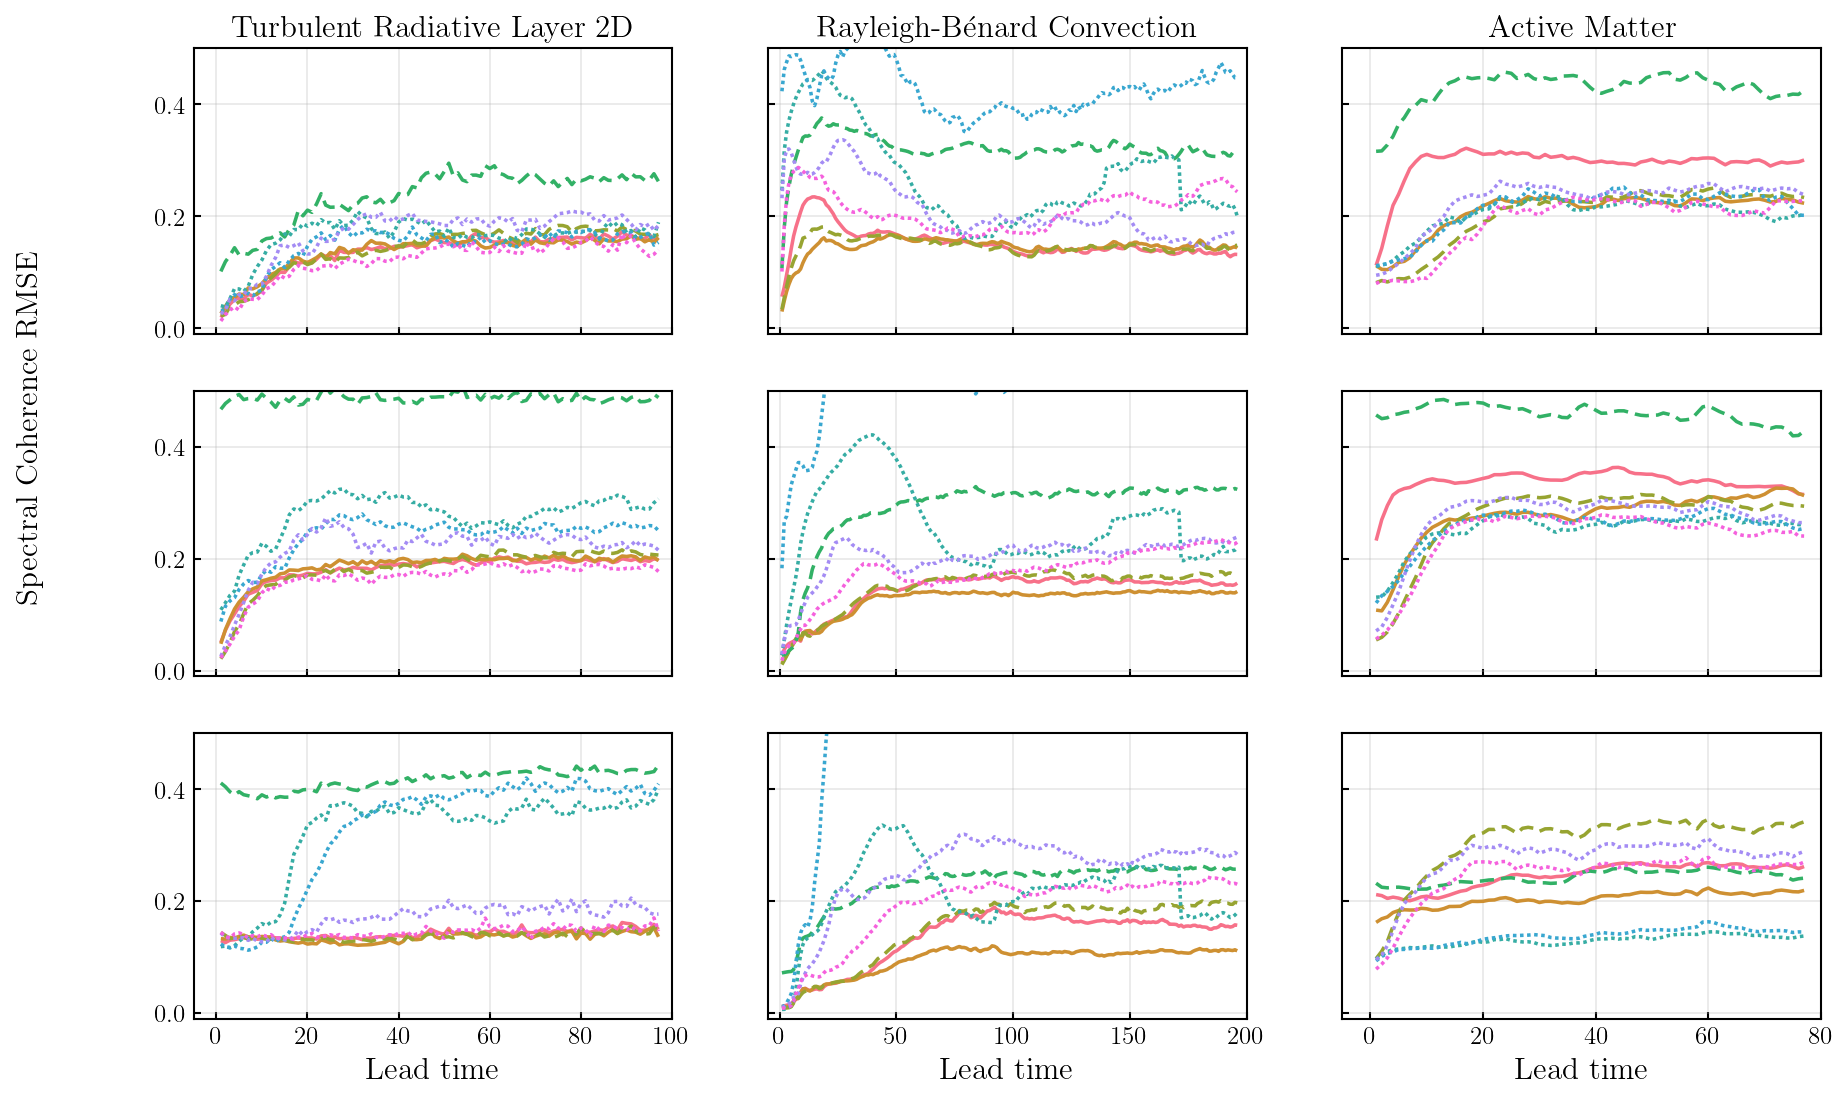

In [7]:
n_pdes, n_bands = len(PDEs), len(bands)

fig1, axs1 = plt.subplots(
    n_bands, n_pdes,
    figsize=(TEXT_WIDTH, ROW_HEIGHT * n_bands),   # ← sized to column width
    sharex="col",
    sharey="row",
)

raw_h, raw_l = None, None

for col, pde in enumerate(PDEs):
    table = stats_df[stats_df["pde"] == pde]
    for row, band in enumerate(bands):
        ax = axs1[row, col]
        sns.lineplot(
            table, x="step", y=f"rmse_c_{band.lower()}",
            hue="model", style="model_type",
            dashes=dashes, estimator=aggregate, errorbar=None,
            palette=model_palette, ax=ax, linewidth=LEGEND_LW,
        )
        if raw_h is None:
            raw_h, raw_l = ax.get_legend_handles_labels()
        ax.get_legend().remove()
        ax.grid(alpha=0.3)
        ax.tick_params(direction="in", which="both", labelsize=12)
        ax.set_xlim(*pde_xlims[pde])
        ax.set_ylim(*band_ylims[band])
        ax.set_xlabel("Lead time" if row == n_bands - 1 else "", fontsize=15)
        ax.set_ylabel("", fontsize=15)
        if col > 0:
            ax.tick_params(labelleft=False, labelsize=12)
        if row == 0:
            ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")

fig1.supylabel("Spectral Coherence RMSE", fontsize=15, x=0.04, y=0.58)

leg_handles, leg_labels = _build_legend(raw_h, raw_l, stats_df)
fig1.tight_layout(pad=0.8)
fig1.subplots_adjust(bottom=0.22, left=0.08, right=0.93)

for row, band in enumerate(bands):
    ax  = axs1[row, -1]
    bb  = ax.get_position()
    fig1.text(
        0.94, (bb.y0 + bb.y1) / 2, band,
        ha="left", va="center",
        rotation=-90, fontsize=15,
        transform=fig1.transFigure,
    )

fig1.legend(
    leg_handles, leg_labels,
    loc="lower center", ncol=4,
    bbox_to_anchor=(0.5, 0.05),
    frameon=True, fontsize=15,
    
)

# ── Save as PDF — vector format, scales perfectly in LaTeX ───────────────────
plt.savefig(
    f"{PROJECT_ROOT}/figures/fig2.pdf",
    dpi=400, bbox_inches="tight", transparent=False,
)

plt.show()

# Figure 2: VRMSE & CRPS 

In [ ]:
pde_metric_ylims = {
    'turbulent_radiative_layer_2D': {
        "VRMSE": (-0.1, 2.0),
        "CRPS":  (-0.03, 1.6),
    },
    'rayleigh_benard': {
        "VRMSE": (-0.1, 2.0),
        "CRPS":  (-0.01, 0.6),
    },
    'active_matter': {
        "VRMSE": (-0.1, 2.0),
        "CRPS":  (-0.01, 0.6),
    },
}

metrics     = ["VRMSE", "CRPS"]
metric_cols = {"VRMSE": "vrmse", "CRPS": "crps"}
n_metrics   = len(metrics)

fig2, axs2 = plt.subplots(
    n_metrics, n_pdes,
    figsize=(TEXT_WIDTH, ROW_HEIGHT * n_metrics),   # ← paper-sized
    sharex="col",
    sharey=False,
)

raw_h, raw_l = None, None

for col, pde in enumerate(PDEs):
    table = stats_df[stats_df["pde"] == pde]
    for row, metric in enumerate(metrics):
        ax = axs2[row, col]
        sns.lineplot(
            table, x="step", y=metric_cols[metric],
            hue="model", style="model_type",
            dashes=dashes, estimator=aggregate, errorbar=None,
            palette=model_palette, ax=ax, linewidth=LEGEND_LW,  # ← thick lines
        )
        if raw_h is None:
            raw_h, raw_l = ax.get_legend_handles_labels()
        ax.get_legend().remove()
        ax.grid(alpha=0.3)
        ax.tick_params(direction="in", which="both", labelsize=12)
        ax.set_xlim(*pde_xlims[pde])

        ylo, yhi = pde_metric_ylims[pde][metric]
        ax.set_ylim(ylo, yhi)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4, prune="both"))

        ax.set_xlabel("Lead time" if row == n_metrics - 1 else "", fontsize=15)

        if col == 0:
            ax.set_ylabel(metric, fontsize=15)
        else:
            ax.set_ylabel("")
            ax.tick_params(labelleft=True, labelsize=12)

        if row == 0:
            ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")

leg_handles, leg_labels = _build_legend(raw_h, raw_l, stats_df)

fig2.align_labels()
fig2.tight_layout(pad=0.8)
fig2.subplots_adjust(bottom=0.22, left=0.08, right=0.93)
fig2.legend(
    leg_handles, leg_labels,
    loc="lower center", ncol=4,
    bbox_to_anchor=(0.5, -0.02),
    frameon=True, fontsize=15,
)

# ── Save as PDF ───────────────────────────────────────────────────────────────
plt.savefig(
    f"{PROJECT_ROOT}/figures/fig3.pdf",
    dpi=400, bbox_inches="tight", transparent=False,
)

plt.show()

# Figure 3: VRMSE Bar Plot across rollout

In [ ]:
TEXT_WIDTH = 12.0    # inches — match your LaTeX \textwidth
BAR_HEIGHT = 2.8    # inches for a single-row bar plot

hatch_lookup = {
    "ours":          "",
    "generative":    "///",
    "deterministic": "x",
}
edgecolor_lookup = {
    "ours":          None,
    "generative":    "white",
    "deterministic": "white",
}

def get_edgecolor(mtype, model_name):
    ec = edgecolor_lookup.get(mtype)
    return ec if ec is not None else model_palette[model_name]

pde_bar_ylims = {
    'turbulent_radiative_layer_2D': (0, 2.0),
    'rayleigh_benard':              (0, 2.0),
    'active_matter':                (0, 4.0),
}

det_lookup = (
    stats_df[["model", "model_type"]]
    .drop_duplicates()
    .set_index("model")["model_type"]
    .to_dict()
)

all_models = model_checklist
n_models   = len(all_models)
bar_width  = 0.8 / n_models

fig, axes = plt.subplots(
    1, n_pdes,
    figsize=(TEXT_WIDTH, BAR_HEIGHT),   # ← paper-sized
    sharey=False,
)

for col, pde in enumerate(PDEs):
    ax       = axes[col]
    table    = stats_df[stats_df["pde"] == pde]
    horizons = sorted(table["horizon"].dropna().unique())

    for h_idx, horizon in enumerate(horizons):
        h_table = table[table["horizon"] == horizon]

        model_vals = (
            h_table.groupby("model")["vrmse"]
            .apply(aggregate)
            .reindex(all_models)
            .dropna()
            .sort_values()
        )

        n_present = len(model_vals)
        offsets   = np.linspace(
            -(n_present - 1) / 2,
             (n_present - 1) / 2,
             n_present,
        ) * bar_width

        for offset, (model_name, val) in zip(offsets, model_vals.items()):
            mtype = det_lookup.get(model_name, "ours")
            ax.bar(
                h_idx + offset, val,
                width=bar_width,
                color=model_palette[model_name],
                hatch=hatch_lookup.get(mtype, ""),
                edgecolor=get_edgecolor(mtype, model_name),
                linewidth=0.4,
            )

    ax.set_xticks(range(len(horizons)))
    ax.set_xticklabels(horizons, fontsize=12)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.tick_params(direction="in", which="both", labelsize=12)
    ax.set_xlabel("Lead Time", fontsize=15)
    ax.set_ylim(*pde_bar_ylims[pde])
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4, prune="both"))
    ax.set_ylabel("VRMSE" if col == 0 else "", fontsize=15)
    if col > 0:
        ax.tick_params(labelleft=True, labelsize=12)
    ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")

# ── Global legend sorted by mean VRMSE across all PDEs ───────────────────────
global_order = (
    stats_df.groupby("model")["vrmse"]
    .apply(aggregate)
    .reindex(all_models)
    .sort_values()
    .dropna()
    .index.tolist()
)

legend_handles = [
    mpatches.Patch(
        facecolor=model_palette[m],
        hatch=hatch_lookup.get(det_lookup.get(m, "ours"), ""),
        edgecolor=get_edgecolor(det_lookup.get(m, "ours"), m),
        label=m,
        linewidth=0.4,
    )
    for m in global_order
]

fig.tight_layout(pad=0.8)
fig.subplots_adjust(bottom=0.22, left=0.08, right=0.93)
fig.legend(
    handles=legend_handles,
    loc="lower center", ncol=4,
    bbox_to_anchor=(0.5, -0.2),
    frameon=True, fontsize=12,
    title_fontsize=7,
)

plt.savefig(
    f"{PROJECT_ROOT}/figures/fig4.pdf",
    dpi=400, bbox_inches="tight", transparent=False,
)
plt.show()

# Tables

In [ ]:
stats_df.columns

In [17]:
PDE = "rayleigh_benard"
#PDE = "turbulent_radiative_layer_2D"
#PDE = "active_matter"

constants = {'rayleigh_benard'              : ["Rayleigh", "Prandtl"],
             'turbulent_radiative_layer_2D' : [],
             'active_matter'                : ['zeta', 'alpha']}

benchmark = ['WaveletFlow_1scale_db2_v4.0', 'WaveletFlow_3scales_db2_v4.0', 
             'FM_data_space_v4.0', 'FNO', 'TFNO', #'FourierFlow_v4.0',
             'UNetClassic', 'UNetConvNext']

benchmark_df = stats_df[
    (stats_df["dataset"] == PDE) &
    (stats_df["model"].isin(benchmark))
]

## Highlight helpers

In [18]:
def highlight_min_per_field_horizon(df: pd.DataFrame) -> pd.DataFrame:
    styles = pd.DataFrame("", index=df.index, columns=df.columns)
    fields = df.index.get_level_values("field").unique()

    for field in fields:
        field_mask = df.index.get_level_values("field") == field
        sub = df.loc[field_mask]

        for col in df.columns:
            # Drop NaNs before finding min to avoid idxmin() errors
            valid = sub[col].dropna()
            if valid.empty:
                continue
            min_idx = valid.idxmin()
            styles.loc[min_idx, col] = "font-weight: bold"

    return styles

def highlight_min_per_horizon(df: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame(
        {col: ["font-weight: bold" if v == df[col].min() else "" for v in df[col]]
         for col in df.columns},
        index=df.index
    )

## 1. Deterministic Scores

In [19]:
per_field = False
metric_to_show = 'vrmse'

if per_field:
    table = benchmark_df[benchmark_df["dataset"] == PDE][["model", "field", "horizon", "vrmse", "rmse", "nrmse", "crps"]]
    table = table.groupby(["model", "field", "horizon"]).agg(aggregate).round(3).reset_index()
    table = table.pivot(index=["model", "field"], columns="horizon", values=[metric_to_show])
else:
    table = benchmark_df[benchmark_df["dataset"] == PDE][["model", "horizon", "vrmse", "rmse", "nrmse", "crps"]]
    table = table.groupby(["model", "horizon"]).agg(aggregate).round(3).reset_index()
    table = table.pivot(index=["model"], columns="horizon", values=[metric_to_show])

#table.style.apply(highlight_min_per_field_horizon, axis=None).format("{:.3f}")  
table.style.apply(highlight_min_per_horizon, axis=None).format("{:.3f}")
# print(table.to_latex(float_format="%.3f"))

## Spectral Scores

#### 1. Average Spectral Coherence RMSE across Bands and Rollout Horizons

In [20]:
band_cols = {"rmse_c_low": "Low", "rmse_c_mid": "Mid", "rmse_c_high": "High"}
#band_cols = {"rmse_p_low": "Low", "rmse_p_mid": "Mid", "rmse_p_high": "High"}

table = benchmark_df[["model", "horizon"] + list(band_cols.keys())]

# Melt bands into long format
table = table.melt(
    id_vars=["model", "horizon"],
    value_vars=list(band_cols.keys()),
    var_name="band",
    value_name="psd_rmse"
)
table["band"] = table["band"].map(band_cols)

# Aggregate
table = table.groupby(["model", "horizon", "band"])["psd_rmse"].agg(aggregate).round(3).reset_index()

# Pivot: rows = model, columns = (band, horizon)
table = table.pivot(index="model", columns=["band", "horizon"], values="psd_rmse")

# Reorder bands
table = table.reindex(columns=["Low", "Mid", "High"], level="band")

table.style.apply(highlight_min_per_horizon, axis=None).format("{:.3f}")

#### 2. Dynamical Regimes: Bands vs Rayleigh and Prandtl numbers

In [ ]:
band_cols = {"rmse_c_low": "Low", "rmse_c_mid": "Mid", "rmse_c_high": "High"}

table = benchmark_df[["model"] + constants[PDE] + list(band_cols.keys())]

# Melt bands into long format
table = table.melt(
    id_vars=["model"] + constants[PDE],
    value_vars=list(band_cols.keys()),
    var_name="band",
    value_name="psd_rmse"
)
table["band"] = table["band"].map(band_cols)

# Aggregate over both rayleigh and prandtl separately

# --- By Rayleigh (aggregates over all Prandtl configs) ---
table_ra = (
    table.groupby(["model", "band", constants[PDE][0]])["psd_rmse"]  # ← add "band"
    .agg(aggregate).round(3).reset_index()
    .pivot(index="model", columns=["band", constants[PDE][0]], values="psd_rmse")
    .reindex(columns=["Low", "Mid", "High"], level="band")
)

# --- By Prandtl (aggregates over all Rayleigh configs) ---
table_pr = (
    table.groupby(["model", "band", constants[PDE][1]])["psd_rmse"]  # ← add "band"
    .agg(aggregate).round(3).reset_index()
    .pivot(index="model", columns=["band", constants[PDE][1]], values="psd_rmse")
    .reindex(columns=["Low", "Mid", "High"], level="band")
)

display(table_ra.style.apply(highlight_min_per_horizon, axis=None).format("{:.3f}"))
display(table_pr.style.apply(highlight_min_per_horizon, axis=None).format("{:.3f}"))

#### 3. Average VRMSE for different Rayleigh and Prandtl numbers 

In [ ]:
table = benchmark_df[["model", "vrmse"] + constants[PDE]]

# Create a combined Ra/Pr label
table["config"] = table.apply(lambda r: f"Ra={r['Rayleigh']}\nPr={r['Prandtl']}", axis=1)

# Aggregate per model / config / horizon
table_cfg = (
    table.groupby(["model", "config"])["vrmse"]
    .agg(aggregate).round(3).reset_index()
    .pivot(index="model", columns=["config"], values="vrmse")
)

display(table_cfg.style.apply(highlight_min_per_horizon, axis=None).format("{:.3f}"))

## Probabilistic

## Rayleigh-Bénard

#### 1. Average Wasserstein distance of the vertical velocity (velocity_y) 

In [ ]:
table = benchmark_df[benchmark_df['field'] == 'velocity_y'][["model", "horizon", "w1"]]

table = (
    table.groupby(["model", "horizon"])
    .agg(aggregate)
    .round(3)
    .reset_index()
)

table = table.pivot(index=["model"], columns="horizon", values=["w1"])

table.style.apply(highlight_min_per_horizon, axis=None).format("{:.3f}")